In [1]:
import pandas as pd
import numpy as np
import databento as db
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
import sys
import os

# Project root: run from the repository or its Notebook folder.
# Alternatively, set PROJECT_ROOT to the repository path.
override = os.environ.get("PROJECT_ROOT")
candidates = [Path(override).expanduser()] if override else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "src" / "backtester.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT to the repository containing src/backtester.py")
sys.path.insert(0, str(ROOT / "src"))
from backtester import load_market_data, session_masks, F_LAST


# Data Extraction and Feature Engineering

To understand how time-related factors affect the current trading strategy, three variables will be analyzed:

1. **Time of Day:** The hour at which each market event occurs, based on Chicago local time.
2. **Time Between Events:** The time elapsed between two consecutive market events (\(t-1\) and \(t\)), measured in milliseconds.
3. **Signal Persistence:** The number of consecutive events in which the same trading signal remains active.

To prepare the dataset for this analysis, the following data preprocessing and feature engineering steps are performed.

We restrict the analysis to market events that meet the backtester's session and order book validity filters. All subsequent calculations use this filtered dataset. Active signal events are not necessarily separate trades.

To reproduce these results, use the six original CL signal files covering October 4–9, 2026, with OBI level 0 and threshold 0.75, together with their matching raw files. Install the repository requirements, restart the kernel, and run all cells.


In [3]:

RAW_DIR = ROOT / "data" / "raw"
SIGNALS_DIR = ROOT / "data" / "signals"

#Check data directories
print("Project root:", ROOT)
print("Raw exists:", RAW_DIR.exists())
print("Signals exists:", SIGNALS_DIR.exists())

Project root: /Users/rodrigo/Desktop/finm-37000-final-project-group-10
Raw exists: True
Signals exists: True


In [4]:
dates = pd.date_range("2026-10-04", "2026-10-09", freq="D")
signal_files = [
    SIGNALS_DIR / f"CL_c_0_mbp-10_{d:%Y-%m-%d}_{d + pd.Timedelta(days=1):%Y-%m-%d}_OBI_levels_0_signals_0_75.parquet"
    for d in dates
]
missing = [str(p) for p in signal_files if not p.is_file()]
if missing:
    raise FileNotFoundError(f"Missing signal files: {missing}")
print(f"Signal files found: {len(signal_files)}")
for file in signal_files:
    print(file.name)


Signal files found: 6
CL_c_0_mbp-10_2026-10-04_2026-10-05_OBI_levels_0_signals_0_75.parquet
CL_c_0_mbp-10_2026-10-05_2026-10-06_OBI_levels_0_signals_0_75.parquet
CL_c_0_mbp-10_2026-10-06_2026-10-07_OBI_levels_0_signals_0_75.parquet
CL_c_0_mbp-10_2026-10-07_2026-10-08_OBI_levels_0_signals_0_75.parquet
CL_c_0_mbp-10_2026-10-08_2026-10-09_OBI_levels_0_signals_0_75.parquet
CL_c_0_mbp-10_2026-10-09_2026-10-10_OBI_levels_0_signals_0_75.parquet


In [5]:
market = load_market_data(signal_files=signal_files, raw_dir=RAW_DIR)
for name in ["ts_recv", "ts_event"]:
    market[name] = pd.to_datetime(market[name], utc=True)
market = market.sort_values("ts_recv", kind="stable").reset_index(drop=True)
original_count = len(market)
in_session, _ = session_masks(market["ts_recv"], flatten_minutes=1.0)
valid_book = (
    ((market["flags"] & F_LAST) > 0)
    & np.isfinite(market["bid_px_00"])
    & np.isfinite(market["ask_px_00"])
    & (market["bid_px_00"] < market["ask_px_00"])
    & (market["bid_sz_00"] > 0)
    & (market["ask_sz_00"] > 0)
)
market = market.loc[in_session & valid_book].copy().reset_index(drop=True)
assert not market.empty
assert market["signal"].isin([-1, 0, 1]).all()
print("Original observations:", original_count)
print("Eligible observations:", len(market))
display(market.head())


Original observations: 12874532
Eligible observations: 12381490


,ts_recv,ts_event,bid_px_00,ask_px_00,bid_sz_00,ask_sz_00,flags,OBI,signal
0,2026-10-04 22:00:00.411848267+00:00,2026-10-04 22:00:00.056248601+00:00,91.7,91.79,2,10,128,-0.666667,0
1,2026-10-04 22:00:00.420304026+00:00,2026-10-04 22:00:00.184403311+00:00,91.7,91.79,1,10,128,-0.818182,-1
2,2026-10-04 22:00:00.422630216+00:00,2026-10-04 22:00:00.251570869+00:00,91.7,91.79,1,9,128,-0.800000,-1
3,2026-10-04 22:00:00.423211773+00:00,2026-10-04 22:00:00.304139921+00:00,91.7,91.79,1,9,128,-0.800000,-1
4,2026-10-04 22:00:00.429114066+00:00,2026-10-04 22:00:00.351479083+00:00,91.7,91.78,1,1,128,0.000000,0


## 1. Time of the Day

In [6]:
# Convert timestamps to Chicago time
local_time = pd.to_datetime(market["ts_event"], utc=True).dt.tz_convert("America/Chicago")
market["day"] = local_time.dt.date
market["hour"] = local_time.dt.hour


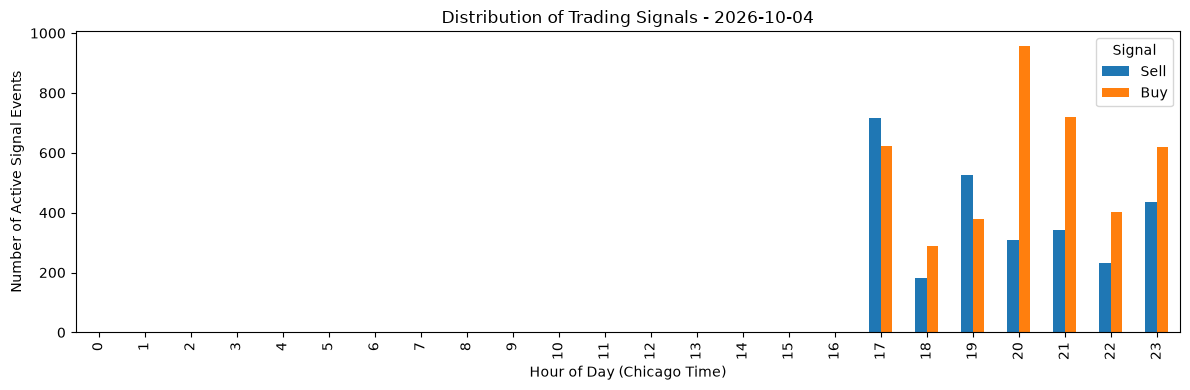

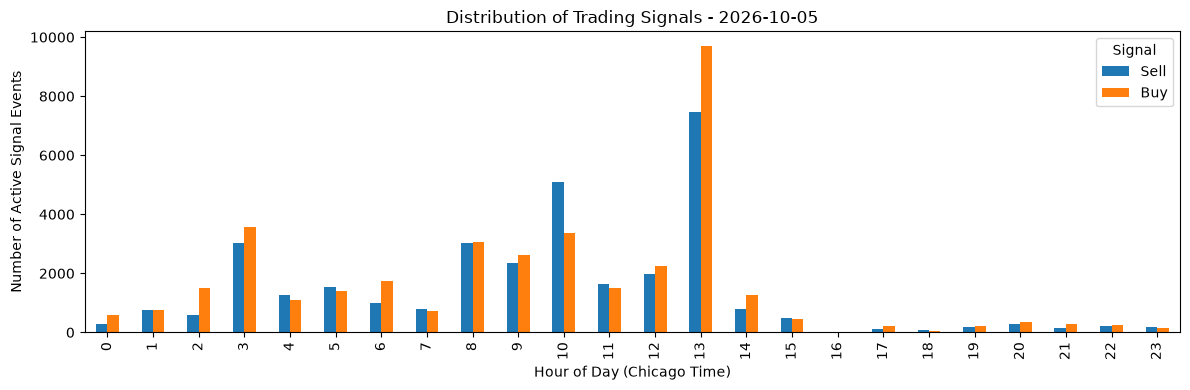

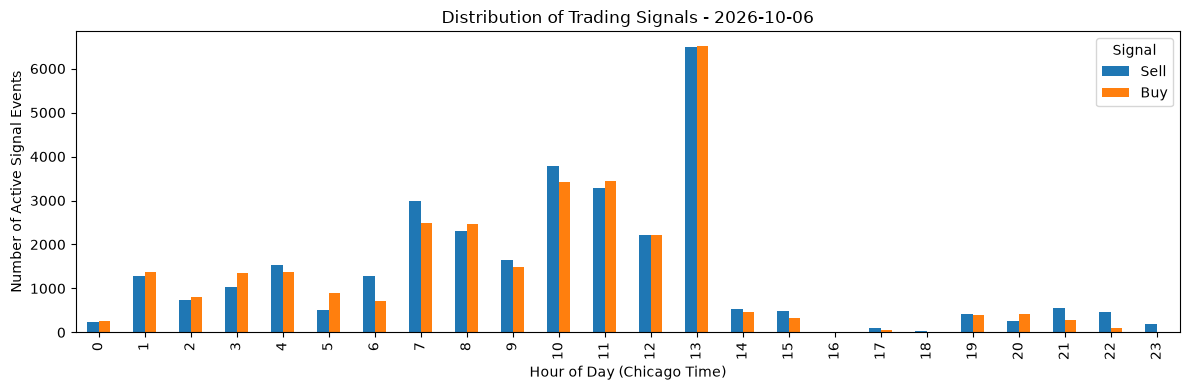

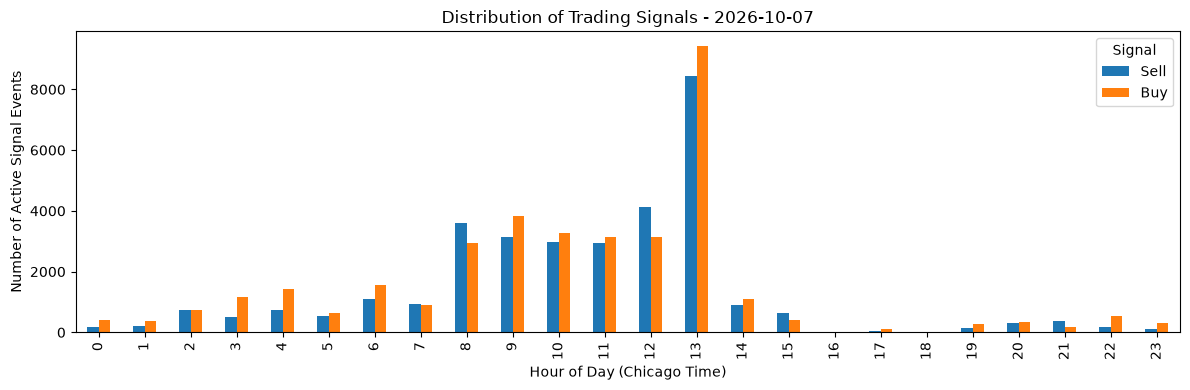

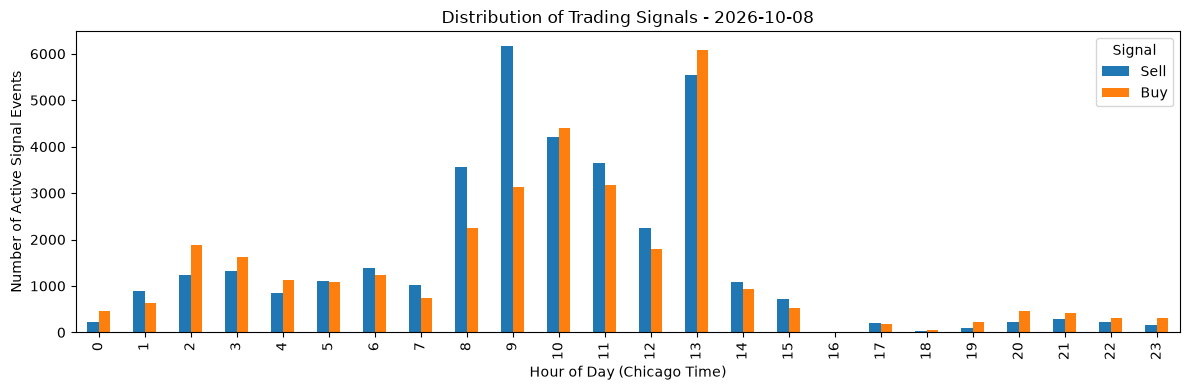

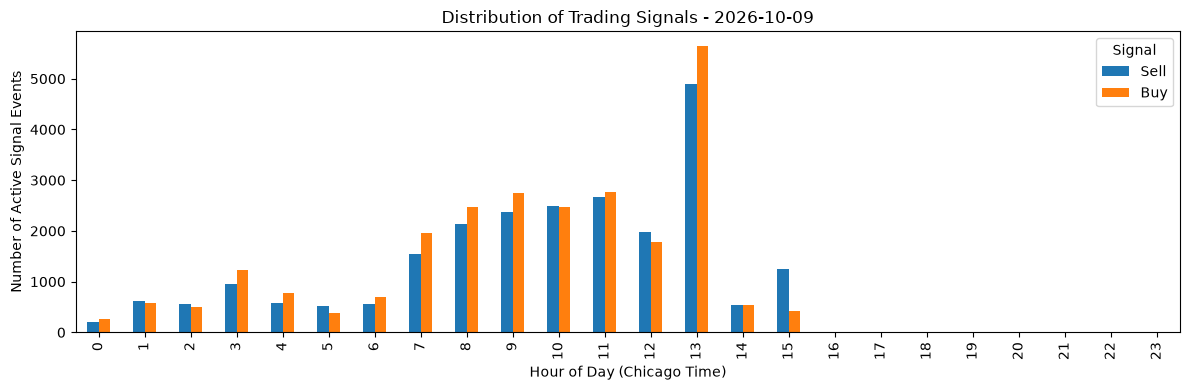

In [7]:
active_signals = market[market["signal"] != 0].copy()

for day, daily_data in active_signals.groupby("day"):

    signals_by_hour = (
        daily_data
        .groupby(["hour", "signal"])
        .size()
        .unstack(fill_value=0)
        .rename(columns={-1: "Sell", 1: "Buy"})
        .reindex(range(24), fill_value=0)
    )

    signals_by_hour.plot(
        kind="bar",
        figsize=(12, 4)
    )

    plt.title(f"Distribution of Trading Signals - {day}")
    plt.xlabel("Hour of Day (Chicago Time)")
    plt.ylabel("Number of Active Signal Events")
    plt.legend(title="Signal")
    plt.tight_layout()
    plt.show()

Analyzing the daily distribution of trading signals, we observe variation in signal activity throughout the day. To distinguish this from differences in overall market activity, we next compare the percentage of eligible events with active signals by hour. The highest pooled percentage occurs at 1:00 PM (Chicago time). To better understand this pattern, we will investigate whether it is related to changes in order book depth or a higher frequency of extreme order book imbalances.

#### 1.1 Trading Signal Frequency Normalized by Market Activity

In [8]:
hourly_daily = (
    market.groupby(["day", "hour"])["signal"]
    .agg(
        total_events="size",
        active_signals=lambda x: (x != 0).sum()
    )
)

hourly_daily["frequency_pct"] = (
    100 * hourly_daily["active_signals"]
    / hourly_daily["total_events"]
)

frequency_table = (
    hourly_daily["frequency_pct"]
    .unstack("day")
)

display(frequency_table)

# Pool event counts across dates rather than averaging daily percentages.
hourly_frequency = hourly_daily[["total_events", "active_signals"]].groupby("hour").sum()
hourly_frequency["frequency_pct"] = 100 * hourly_frequency["active_signals"] / hourly_frequency["total_events"]
display(hourly_frequency)


day,2026-10-04,2026-10-05,2026-10-06,2026-10-07,2026-10-08,2026-10-09
hour,,,,,,
0,NaN,1.755413,1.523146,1.495480,1.284931,0.857281
1,NaN,1.721106,2.309863,0.988352,1.744996,1.427032
2,NaN,1.625371,1.268516,1.062147,2.159074,1.253193
3,NaN,1.964538,1.354481,1.190326,1.846699,1.630414
4,NaN,1.761426,1.880381,1.747160,1.834348,1.624499
5,NaN,1.947126,1.546179,1.162062,1.787788,1.259508
6,NaN,1.957201,2.086661,2.105238,2.011528,1.334723
7,NaN,1.230722,2.952419,1.339669,1.422245,2.313947
8,NaN,2.482430,2.259174,3.153964,2.721788,2.050210


,total_events,active_signals,frequency_pct
hour,,,
0,228434,3097,1.355753
1,434345,7488,1.723975
2,616447,9276,1.504752
3,946237,15783,1.667975
4,605137,10791,1.783233
5,538595,8631,1.602503
6,586116,11268,1.922486
7,718729,14069,1.957483
8,1101181,27793,2.523927


To better understand the increase in trading signals at 1:00 PM, we analyzed the percentage of market events that generate an active Buy or Sell signal during each hour. This allows us to determine whether the higher number of signals is simply related to greater market activity or whether extreme order book imbalances are actually more frequent at certain times.

The results show that approximately 7.72% of market events at 1:00 PM generate an active trading signal, with percentages ranging from 5.43% to 10.75% across the five trading days analyzed. __This suggests that the increase in signals at 1:00 PM is not only explained by a higher number of market events, but also by a greater frequency of extreme order book imbalances__. Therefore, this hour appears particularly interesting for further analysis, although we still need to determine whether these signals lead to better trading performance.

The overall percentage pools active and total eligible events across dates; it is not the simple average of daily percentages.

#### 1.2 Order Book Depth and Imbalance Analysis

In [9]:
market["top_level_depth"] = (
    market["bid_sz_00"] + market["ask_sz_00"]
)

hourly_depth = (
    market.groupby("hour")
    .agg(
        avg_bid_size=("bid_sz_00", "mean"),
        avg_ask_size=("ask_sz_00", "mean"),
        avg_total_depth=("top_level_depth", "mean")
    )
)

display(hourly_depth)

,avg_bid_size,avg_ask_size,avg_total_depth
hour,,,
0,3.199051,2.993057,6.192108
1,3.514708,3.518977,7.033685
2,3.592138,3.438651,7.030789
3,3.529476,3.408332,6.937808
4,3.607917,3.530579,7.138496
5,3.476323,3.417822,6.894145
6,3.507033,3.535829,7.042862
7,3.700155,3.683139,7.383295
8,4.005977,4.064029,8.070007


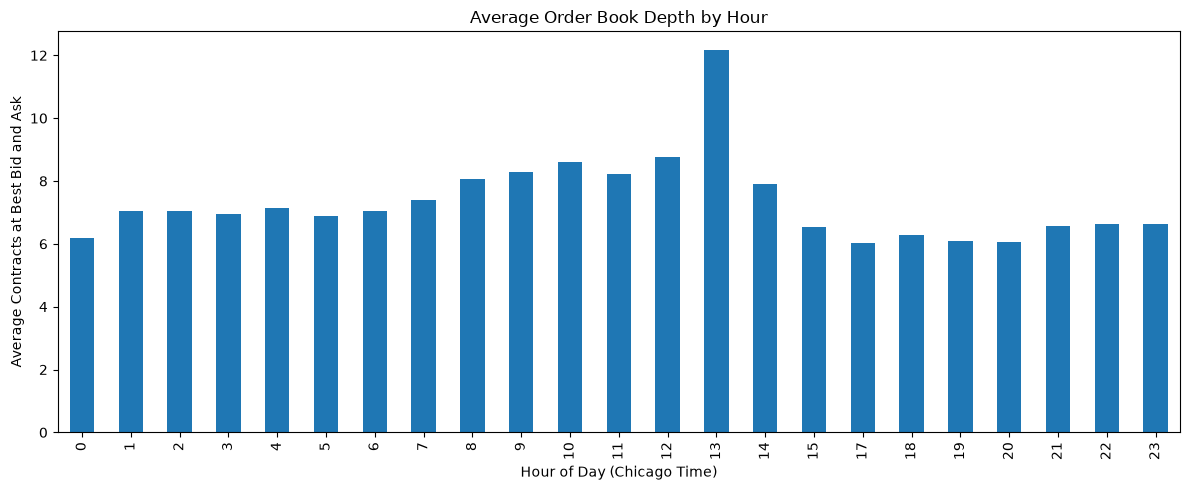

In [10]:
hourly_depth["avg_total_depth"].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Average Order Book Depth by Hour")
plt.xlabel("Hour of Day (Chicago Time)")
plt.ylabel("Average Contracts at Best Bid and Ask")
plt.tight_layout()
plt.show()

The order book depth was calculated for each hour as the sum of the contracts available at the best bid and ask prices:

$$
Depth = BidSize + AskSize
$$

The results show that the highest average order book depth occurs at 1:00 PM, with approximately 12.16 contracts. However, higher depth does not necessarily mean that the order book is balanced. Therefore, as a next step, we calculate the __absolute OBI__ to determine whether the available contracts are evenly distributed between the bid and ask sides or whether significant imbalances exist.

In [11]:
# Calculate absolute OBI
market["abs_OBI"] = market["OBI"].abs()

# Calculate hourly averages
hourly_obi = (
    market.groupby("hour")
    .agg(
        avg_abs_OBI=("abs_OBI", "mean"),
        avg_bid_size=("bid_sz_00", "mean"),
        avg_ask_size=("ask_sz_00", "mean")
    )
)

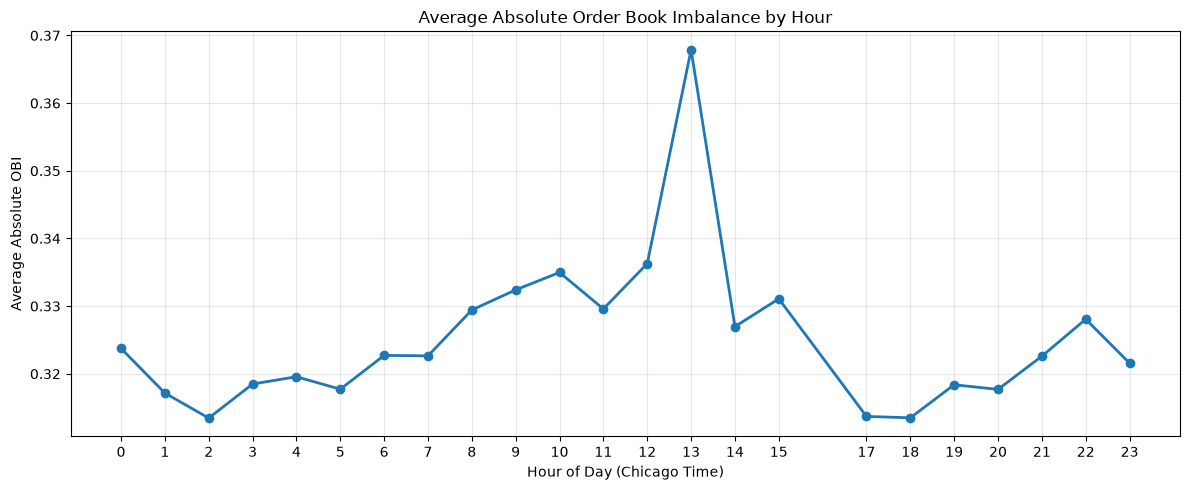

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_obi.index,
    hourly_obi["avg_abs_OBI"],
    marker="o",
    linewidth=2
)

plt.title("Average Absolute Order Book Imbalance by Hour")
plt.xlabel("Hour of Day (Chicago Time)")
plt.ylabel("Average Absolute OBI")
plt.xticks(hourly_obi.index)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

We can observe that the average absolute OBI reaches its highest value at 1:00 PM, suggesting that the order book is more imbalanced during this hour. 

Combined with the previous results, this indicates that higher order book depth does not necessarily mean that the number of contracts available at the bid and ask prices is evenly distributed. In fact, at 1:00 PM, we observe both higher average depth and stronger order book imbalances.

## 2. Time Between Market Events

Next, we analyze how quickly market events occur and whether there is a difference between events that generate trading signals and those that do not. Specifically, we want to determine whether active Buy or Sell signals are associated with shorter time intervals between consecutive market events.

The time between events is calculated as the difference between the timestamps of two consecutive eligible events within the same trading session:

$$
\Delta t_i = t_i - t_{i-1}
$$

where $t_i$ represents the reception timestamp of event $i$. The resulting time intervals are measured in milliseconds.

Intervals are calculated after filtering, so they measure time between eligible records rather than between all original feed messages.


In [13]:
# Convert timestamps
ts = pd.to_datetime(market["ts_recv"], utc=True)

# Identify trading sessions (17:00 Chicago time)
chicago_time = ts.dt.tz_convert("America/Chicago")

session = (
    chicago_time.dt.tz_localize(None) - pd.Timedelta(hours=17)
).dt.date

# Time between consecutive market events, in milliseconds
market["time_between_events_ms"] = (
    ts.groupby(session)
      .diff()
      .dt.total_seconds() * 1000
)

display(
    market[["ts_recv", "signal", "time_between_events_ms"]].head(10)
)

,ts_recv,signal,time_between_events_ms
0,2026-10-04 22:00:00.411848267+00:00,0,NaN
1,2026-10-04 22:00:00.420304026+00:00,-1,8.455759
2,2026-10-04 22:00:00.422630216+00:00,-1,2.326190
3,2026-10-04 22:00:00.423211773+00:00,-1,0.581557
4,2026-10-04 22:00:00.429114066+00:00,0,5.902293
5,2026-10-04 22:00:00.429217797+00:00,0,0.103731
6,2026-10-04 22:00:00.429351288+00:00,0,0.133491
7,2026-10-04 22:00:00.430491901+00:00,0,1.140613
8,2026-10-04 22:00:00.432454979+00:00,0,1.963078
9,2026-10-04 22:00:00.433090448+00:00,0,0.635469


In [14]:
event_analysis = market[
    market["time_between_events_ms"].notna()
    & np.isfinite(market["time_between_events_ms"])
    & (market["time_between_events_ms"] >= 0)
].copy()

event_analysis["signal_type"] = event_analysis["signal"].map({
    -1: "Sell",
     0: "No Signal",
     1: "Buy"
})

event_summary = (
    event_analysis.groupby("signal_type")["time_between_events_ms"]
    .agg(
        total_events="count",
        mean_ms="mean",
        median_ms="median",
        p90_ms=lambda x: x.quantile(0.90)
    )
)

display(event_summary.round(4))

,total_events,mean_ms,median_ms,p90_ms
signal_type,,,,
Buy,166398,21.2689,0.2343,12.9685
No Signal,12053431,33.7781,0.2773,43.9278
Sell,161656,20.5233,0.2364,11.7815


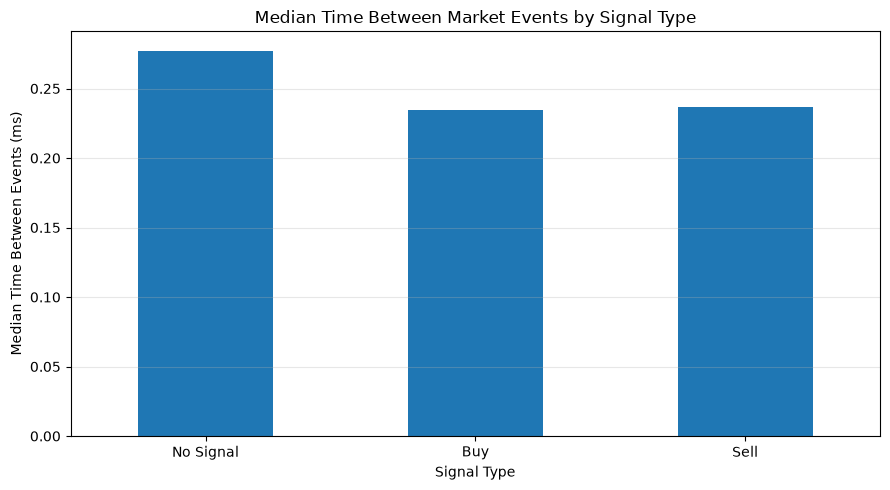

In [15]:
order = ["No Signal", "Buy", "Sell"]

ax = event_summary.loc[order, "median_ms"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Median Time Between Market Events by Signal Type")
plt.xlabel("Signal Type")
plt.ylabel("Median Time Between Events (ms)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

The results show that events generating active trading signals tend to have shorter time intervals than events without signals. On average, Buy and Sell signals have intervals of 21.27 ms and 20.52 ms, respectively, compared to 33.78 ms for events without signals. This represents approximately a 37% reduction for Buy and a 39% reduction for Sell in the average time between events.

Additionally, Buy and Sell signals exhibit very similar time intervals, suggesting that this pattern is consistent regardless of signal direction. Overall, these findings suggest that extreme order book imbalances are associated with shorter intervals between market events. However, further analysis is needed to determine whether this relationship improves the predictive performance of the trading strategy.

The corresponding medians are 0.2343 ms for Buy, 0.2364 ms for Sell, and 0.2773 ms without a signal. Means are more sensitive to long intervals, and these comparisons are descriptive.

# 3. Signal Persistence Analysis

Finally, we analyze signal persistence to determine how many consecutive market events maintain the same Buy or Sell signal. The objective is to understand whether trading signals tend to disappear immediately or remain active across multiple events. We also want to investigate whether Buy and Sell signals exhibit different persistence patterns and whether periods with higher signal frequency, such as 1:00 PM, are associated with more persistent signals.

In [16]:
# Identify changes in signal or trading session
new_group = (
    market["signal"].ne(market["signal"].shift())
    | session.ne(session.shift())
)

# Count consecutive events with the same signal
market["signal_persistence"] = (
    market.groupby(new_group.cumsum()).cumcount() + 1
)

# Neutral events have zero persistence
market.loc[
    market["signal"] == 0,
    "signal_persistence"
] = 0

display(
    market[["ts_recv", "OBI", "signal", "signal_persistence"]].head(20)
)

,ts_recv,OBI,signal,signal_persistence
0,2026-10-04 22:00:00.411848267+00:00,-0.666667,0,0
1,2026-10-04 22:00:00.420304026+00:00,-0.818182,-1,1
2,2026-10-04 22:00:00.422630216+00:00,-0.800000,-1,2
3,2026-10-04 22:00:00.423211773+00:00,-0.800000,-1,3
4,2026-10-04 22:00:00.429114066+00:00,0.000000,0,0
5,2026-10-04 22:00:00.429217797+00:00,0.000000,0,0
6,2026-10-04 22:00:00.429351288+00:00,-0.333333,0,0
7,2026-10-04 22:00:00.430491901+00:00,0.000000,0,0
8,2026-10-04 22:00:00.432454979+00:00,-0.333333,0,0
9,2026-10-04 22:00:00.433090448+00:00,0.000000,0,0


In [17]:
# Identify each consecutive signal sequence
market["run_id"] = new_group.cumsum()
market["session"] = session

# Runs touching a session boundary may be incomplete.
boundary_ids = (
    set(market.groupby("session")["run_id"].first())
    | set(market.groupby("session")["run_id"].last())
)
signal_runs = (
    market[market["signal"] != 0].groupby("run_id")
    .agg(signal=("signal", "first"), persistence=("signal_persistence", "max"),
         start_hour=("hour", "first"))
)
assert signal_runs["persistence"].sum() == market["signal"].ne(0).sum()
print("Boundary runs excluded:", signal_runs.index.isin(boundary_ids).sum())
signal_runs = signal_runs.loc[~signal_runs.index.isin(boundary_ids)].copy()
signal_runs["signal_type"] = signal_runs["signal"].map({1: "Buy", -1: "Sell"})
persistence_summary = signal_runs.groupby("signal_type")["persistence"].agg(
    total_sequences="count", mean_events="mean", median_events="median", max_events="max")
display(persistence_summary)

# Assign each run to the Chicago hour of its first eligible event.
persistence_by_hour = signal_runs.groupby("start_hour")["persistence"].agg(
    total_sequences="count", mean_events="mean", median_events="median")
display(persistence_by_hour)


Boundary runs excluded: 2


,total_sequences,mean_events,median_events,max_events
signal_type,,,,
Buy,62805,2.649439,2.0,94
Sell,60679,2.663755,2.0,263


,total_sequences,mean_events,median_events
start_hour,,,
0,1263,2.452098,2.0
1,3011,2.486881,1.0
2,3846,2.411856,1.0
3,6505,2.426287,1.0
4,4528,2.383171,1.0
5,3535,2.441584,1.0
6,4149,2.715835,2.0
7,5272,2.668627,2.0
8,10576,2.627931,2.0


Signal persistence was calculated by counting the number of consecutive market events with the same Buy or Sell signal. The counter increases while the signal remains unchanged and resets when the signal changes, becomes neutral, or a new trading session begins. We then calculated the average, median, and maximum persistence for each signal type.

Sequences touching the beginning or end of a session were excluded from the summary because they may be incomplete. Persistence is measured in eligible events, not elapsed time.


The results show that Buy and Sell signals have very similar persistence patterns, with averages of 2.65 and 2.66 consecutive events, respectively, and a median of 2 events for both. Although some sequences reach 94 events for Buy and 263 for Sell, signals generally span few eligible events. This suggests that extreme order book imbalances tend to persist across few eligible events, which could be important when evaluating signal stability and trading execution.

Sequences starting at 1:00 PM average 2.87 events, compared with 2.66 across all included sequences. Each sequence is assigned to its starting hour.

# 4. Conclusions

The analysis suggests that temporal factors are relevant to understanding the behavior of OBI trading signals. By examining time of day, time between market events, and signal persistence, we identified several patterns that could be useful for evaluating and potentially improving the trading strategy.

- **Time of Day:** Trading signals are not uniformly distributed throughout the day. At 1:00 PM (Chicago time), approximately 7.72% of market events generate active signals, the highest hourly frequency observed.

- **Order Book Depth and Imbalance:** At 1:00 PM, average top-of-book depth reaches 12.16 contracts, while average absolute OBI reaches 0.368. This suggests that higher visible depth can coexist with stronger order book imbalances.

- **Time Between Events:** Buy and Sell signals are associated with shorter preceding event intervals, averaging 21.27 ms and 20.52 ms, respectively, compared with 33.78 ms for events without signals.

- **Signal Persistence:** Buy and Sell signals have similar persistence patterns, averaging 2.65 and 2.66 consecutive events, respectively, with a median of 2 events for both.

- **Implications for the Strategy:** These findings suggest that temporal characteristics may help identify differences in signal behavior. However, further backtesting is needed to determine whether these patterns improve predictive accuracy, profitability, or execution performance.

These findings apply to the filtered sample and should be checked over more weeks. Hourly averages do not establish an event-level causal relationship, and persistence in event counts does not measure elapsed duration.